# Bookstore Intelligence Mission
Scraping https://books.toscrape.com/ into a clean dataset for business decisions.

## Mission 1 Reconnaissance
| Data | HTML tag / class | Notes |
|---|---|---|
| Title | `<h3><a title="...">` | Visible text is cut short, so the `title` attribute is used |
| Price | `<p class="price_color">` | `£51.77` cleaned to `51.77` |
| Rating | `<p class="star-rating Three">` | Rating is the second class name, mapped to 1–5 |
| Availability | `<p class="instock availability">` | Whitespace stripped |

In [2]:
import re
import time
from urllib.parse import urljoin

import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

BASE_URL = "https://books.toscrape.com/"
MAX_PAGES = 5
BUDGET = 100
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}


def get_soup(url):
    response = requests.get(url, timeout=10)
    response.raise_for_status()
    response.encoding = "utf-8"
    return BeautifulSoup(response.text, "html.parser")


soup = get_soup(BASE_URL)
first_card = soup.find("article", class_="product_pod")
print(first_card.prettify())

<article class="product_pod">
 <div class="image_container">
  <a href="catalogue/a-light-in-the-attic_1000/index.html">
   <img alt="A Light in the Attic" class="thumbnail" src="media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg"/>
  </a>
 </div>
 <p class="star-rating Three">
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
 </p>
 <h3>
  <a href="catalogue/a-light-in-the-attic_1000/index.html" title="A Light in the Attic">
   A Light in the ...
  </a>
 </h3>
 <div class="product_price">
  <p class="price_color">
   £51.77
  </p>
  <p class="instock availability">
   <i class="icon-ok">
   </i>
   In stock
  </p>
  <form>
   <button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">
    Add to basket
   </button>
  </form>
 </div>
</article>



## Mission 2 Scrape the first page

In [3]:
def parse_books(soup, page_url):
    books = []
    for card in soup.find_all("article", class_="product_pod"):
        link = card.h3.a
        title = link["title"]
        price_text = card.find("p", class_="price_color").get_text()
        price = float(re.sub(r"[^0-9.]", "", price_text))
        rating_classes = card.find("p", class_="star-rating")["class"]
        rating = next(RATING_MAP[c] for c in rating_classes if c in RATING_MAP)
        availability = card.find("p", class_="availability").get_text(strip=True)
        product_url = urljoin(page_url, link["href"])

        books.append({
            "Title": title,
            "Price": price,
            "Rating": rating,
            "Availability": availability,
            "Product_URL": product_url,
        })
    return books


first_page = parse_books(soup, BASE_URL)
print(f"\nBooks on page 1: {len(first_page)}")
print(pd.DataFrame(first_page).head())


Books on page 1: 20
                                   Title  Price  Rating Availability                                        Product_URL
0                   A Light in the Attic  51.77       3     In stock  https://books.toscrape.com/catalogue/a-light-i...
1                     Tipping the Velvet  53.74       1     In stock  https://books.toscrape.com/catalogue/tipping-t...
2                             Soumission  50.10       1     In stock  https://books.toscrape.com/catalogue/soumissio...
3                          Sharp Objects  47.82       4     In stock  https://books.toscrape.com/catalogue/sharp-obj...
4  Sapiens: A Brief History of Humankind  54.23       5     In stock  https://books.toscrape.com/catalogue/sapiens-a...


## Mission 3 Scrape 5 pages with a loop and save competitor_books.csv

In [4]:
def scrape_catalogue(start_url, max_pages=None, delay=1):
    all_books = []
    url = start_url
    page = 0

    while url and (max_pages is None or page < max_pages):
        page += 1
        page_soup = get_soup(url)
        books = parse_books(page_soup, url)
        all_books.extend(books)
        print(f"Page {page}: {len(books)} books")

        next_button = page_soup.select_one("li.next a")
        url = urljoin(url, next_button["href"]) if next_button else None
        if url:
            time.sleep(delay)

    return all_books


df = pd.DataFrame(scrape_catalogue(BASE_URL, max_pages=MAX_PAGES))
df = df.drop_duplicates(subset="Product_URL").reset_index(drop=True)

print(f"\nTotal books: {len(df)}")
print(df.head())
print("\nColumn types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())

df.to_csv("competitor_books.csv", index=False, encoding="utf-8-sig")
print("\nSaved competitor_books.csv")

Page 1: 20 books
Page 2: 20 books
Page 3: 20 books
Page 4: 20 books
Page 5: 20 books

Total books: 100
                                   Title  Price  Rating Availability                                        Product_URL
0                   A Light in the Attic  51.77       3     In stock  https://books.toscrape.com/catalogue/a-light-i...
1                     Tipping the Velvet  53.74       1     In stock  https://books.toscrape.com/catalogue/tipping-t...
2                             Soumission  50.10       1     In stock  https://books.toscrape.com/catalogue/soumissio...
3                          Sharp Objects  47.82       4     In stock  https://books.toscrape.com/catalogue/sharp-obj...
4  Sapiens: A Brief History of Humankind  54.23       5     In stock  https://books.toscrape.com/catalogue/sapiens-a...

Column types:
 Title               str
Price           float64
Rating            int64
Availability        str
Product_URL         str
dtype: object

Missing values:
 Title    

## Mission 4 Intelligence Analysis

In [5]:
print("\n MISSION 4: INTELLIGENCE ANALYSIS ")

most_expensive = df.loc[df["Price"].idxmax()]
cheapest = df.loc[df["Price"].idxmin()]
avg_price = df["Price"].mean()
five_star_count = int((df["Rating"] == 5).sum())
in_stock_pct = df["Availability"].str.contains("In stock", case=False).mean() * 100
top5 = df.sort_values(["Rating", "Price"], ascending=[False, True]).head(5)
five_star = df[df["Rating"] == 5]
cheapest_five_star = five_star.loc[five_star["Price"].idxmin()]

print(f"1. Most expensive : {most_expensive['Title']} (£{most_expensive['Price']:.2f})")
print(f"2. Cheapest       : {cheapest['Title']} (£{cheapest['Price']:.2f})")
print(f"3. Average price  : £{avg_price:.2f}")
print(f"4. 5-star books   : {five_star_count}")
print(f"5. In stock       : {in_stock_pct:.1f}%")
print("6. Top 5 highest-rated:")
print(top5[["Title", "Price", "Rating"]].to_string(index=False))
print(f"7. Cheapest 5-star: {cheapest_five_star['Title']} (£{cheapest_five_star['Price']:.2f})")


 MISSION 4: INTELLIGENCE ANALYSIS 
1. Most expensive : The Death of Humanity: and the Case for Life (£58.11)
2. Cheapest       : Patience (£10.16)
3. Average price  : £34.56
4. 5-star books   : 19
5. In stock       : 100.0%
6. Top 5 highest-rated:
                                                                            Title  Price  Rating
                                 Princess Between Worlds (Wide-Awake Princess #5)  13.34       5
Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Princess Jellyfish 2-in-1 Omnibus #1)  13.61       5
                                                                   Sophie's World  15.94       5
                                                                           Thirst  17.27       5
                                                                      Set Me Free  17.46       5
7. Cheapest 5-star: Princess Between Worlds (Wide-Awake Princess #5) (£13.34)


## Business Decision

In [6]:
print("\n BUSINESS DECISION ")

shortlist = (
    df[(df["Rating"] >= 4) & (df["Price"] < avg_price)]
    .sort_values(["Rating", "Price"], ascending=[False, True])
)
high_rated_pct = (df["Rating"] >= 4).mean() * 100

print(f"Evidence 1: {high_rated_pct:.0f}% of books are rated 4-5 stars")
print(f"Evidence 2: {len(shortlist)} of them are priced below the £{avg_price:.2f} average")
print("\nAverage price by rating:")
print(df.groupby("Rating")["Price"].mean().round(2).to_string())
print("\nPriority shortlist (top 10):")
print(shortlist[["Title", "Price", "Rating"]].head(10).to_string(index=False))


 BUSINESS DECISION 
Evidence 1: 37% of books are rated 4-5 stars
Evidence 2: 21 of them are priced below the £34.56 average

Average price by rating:
Rating
1    35.52
2    35.91
3    36.84
4    33.98
5    30.01

Priority shortlist (top 10):
                                                                             Title  Price  Rating
                                  Princess Between Worlds (Wide-Awake Princess #5)  13.34       5
 Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Princess Jellyfish 2-in-1 Omnibus #1)  13.61       5
                                                                    Sophie's World  15.94       5
                                                                            Thirst  17.27       5
                                                                       Set Me Free  17.46       5
                        The Four Agreements: A Practical Guide to Personal Freedom  17.66       5
The Inefficiency Assassin: Time Management Tactics for Working Smarter,

## CEO £100 Challenge
Knapsack optimisation: finds the combination with the highest total stars within £100, not just the cheapest books.

In [7]:
print("\n CEO £100 CHALLENGE ")

def best_purchase(data, budget):
    costs = (data["Price"] * 100).round().astype(int).to_numpy()
    stars = data["Rating"].to_numpy()
    cap = int(budget * 100)
    n = len(data)

    best = np.zeros(cap + 1, dtype=int)
    took = np.zeros((n, cap + 1), dtype=bool)

    for i in range(n):
        c, s = costs[i], stars[i]
        if c > cap:
            continue
        with_book = best[: cap + 1 - c] + s
        improved = with_book > best[c:]
        took[i, c:] = improved
        best[c:] = np.where(improved, with_book, best[c:])

    b = int(np.argmax(best == best[cap]))
    chosen = []
    for i in range(n - 1, -1, -1):
        if took[i, b]:
            chosen.append(i)
            b -= costs[i]
    return data.iloc[chosen[::-1]]


basket = best_purchase(df, BUDGET)
print(basket[["Title", "Price", "Rating"]].to_string(index=False))
print(f"\nBooks bought      : {len(basket)}")
print(f"Total cost        : £{basket['Price'].sum():.2f}")
print(f"Total star rating : {basket['Rating'].sum()}")


 CEO £100 CHALLENGE 
                                                                              Title  Price  Rating
                                                                     Sophie's World  15.94       5
                                            Untitled Collection: Sabbath Poems 2014  14.27       4
                                                                             Thirst  17.27       5
  Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Princess Jellyfish 2-in-1 Omnibus #1)  13.61       5
                                   Princess Between Worlds (Wide-Awake Princess #5)  13.34       5
                                                                           Patience  10.16       3
Mama Tried: Traditional Italian Cooking for the Screwed, Crude, Vegan, and Tattooed  14.02       4

Books bought      : 7
Total cost        : £98.61
Total star rating : 31


## Bonus 3 & 4 Books per star rating


 BONUS: RATING COUNTS 
Rating
1    22
2    19
3    22
4    18
5    19


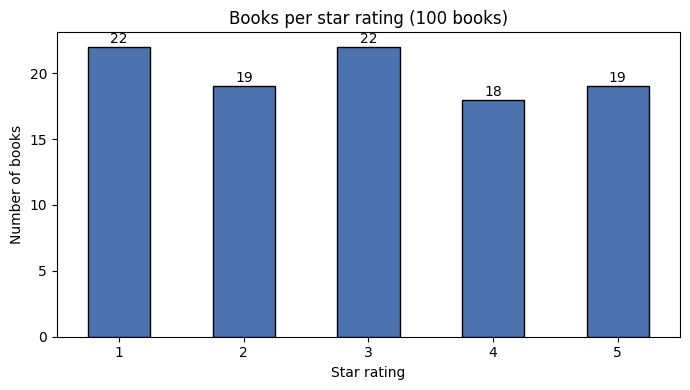

In [8]:
print("\n BONUS: RATING COUNTS ")
rating_counts = df["Rating"].value_counts().sort_index()
print(rating_counts.to_string())

ax = rating_counts.plot(kind="bar", color="#4C72B0", edgecolor="black", figsize=(7, 4))
ax.set_title(f"Books per star rating ({len(df)} books)")
ax.set_xlabel("Star rating")
ax.set_ylabel("Number of books")
ax.tick_params(axis="x", rotation=0)
for i, v in enumerate(rating_counts):
    ax.text(i, v + 0.3, str(v), ha="center")
plt.tight_layout()
plt.savefig("rating_counts.png", dpi=150)
plt.show()

## Boss Level All catalogue pages
Same `scrape_catalogue` function with `max_pages=None`: it follows the next button until the last page. The analysis above stays on the 5-page dataset.

In [9]:
all_df = pd.DataFrame(scrape_catalogue(BASE_URL, max_pages=None))
print(f"\nBoss Level: {len(all_df)} books scraped from every catalogue page")
print(all_df["Rating"].value_counts().sort_index().to_string())

Page 1: 20 books
Page 2: 20 books
Page 3: 20 books
Page 4: 20 books
Page 5: 20 books
Page 6: 20 books
Page 7: 20 books
Page 8: 20 books
Page 9: 20 books
Page 10: 20 books
Page 11: 20 books
Page 12: 20 books
Page 13: 20 books
Page 14: 20 books
Page 15: 20 books
Page 16: 20 books
Page 17: 20 books
Page 18: 20 books
Page 19: 20 books
Page 20: 20 books
Page 21: 20 books
Page 22: 20 books
Page 23: 20 books
Page 24: 20 books
Page 25: 20 books
Page 26: 20 books
Page 27: 20 books
Page 28: 20 books
Page 29: 20 books
Page 30: 20 books
Page 31: 20 books
Page 32: 20 books
Page 33: 20 books
Page 34: 20 books
Page 35: 20 books
Page 36: 20 books
Page 37: 20 books
Page 38: 20 books
Page 39: 20 books
Page 40: 20 books
Page 41: 20 books
Page 42: 20 books
Page 43: 20 books
Page 44: 20 books
Page 45: 20 books
Page 46: 20 books
Page 47: 20 books
Page 48: 20 books
Page 49: 20 books
Page 50: 20 books

Boss Level: 1000 books scraped from every catalogue page
Rating
1    226
2    196
3    203
4    179
5    196

## Results

**Mission 4 Intelligence Analysis (100 books, 5 pages)**
1. Most expensive: *The Death of Humanity: and the Case for Life* £58.11
2. Cheapest: *Patience* £10.16
3. Average price: £34.56
4. 5-star books: 19
5. In stock: 100%
6. Top 5 highest-rated (all 5 stars; ties ranked by lowest price):
   *Princess Between Worlds* (£13.34), *Princess Jellyfish 2-in-1 Omnibus, Vol. 01* (£13.61), *Sophie's World* (£15.94), *Thirst* (£17.27), *Set Me Free* (£17.46)
7. Cheapest 5-star book: *Princess Between Worlds (Wide-Awake Princess #5)* £13.34

**CEO £100 Challenge**
| Title | Price | Rating |
|---|---|---|
| Sophie's World | £15.94 | 5 |
| Untitled Collection: Sabbath Poems 2014 | £14.27 | 4 |
| Thirst | £17.27 | 5 |
| Princess Jellyfish 2-in-1 Omnibus, Vol. 01 | £13.61 | 5 |
| Princess Between Worlds | £13.34 | 5 |
| Patience | £10.16 | 3 |
| Mama Tried: Traditional Italian Cooking | £14.02 | 4 |
| **Total (7 books)** | **£98.61** | **31 stars** |

**Business Recommendation**
We should prioritise the 21 books rated 4–5 stars that sell below the competitor's £34.56 average price, such as *Sophie's World* (£15.94) and *The Four Agreements* (£17.66). The competitor's 5-star books are its cheapest rating group (average £30.01, compared with £35.52–£36.84 for 1–3 star books), so top-rated titles can be offered without premium pricing. With 100% of the competitor's range in stock, availability is not a differentiator, which makes high-rating, low-price titles our clearest advantage.